# HCO VNLS làm trọng tâm

Notebook này kiểm tra đúng câu hỏi của đề tài: **HCO+VNLS có tìm được bộ đặc trưng tốt hơn HCO và VNLS độc lập khi dùng cùng model học máy, cùng dữ liệu và cùng ngân sách hay không?**

- HCO: đối chứng tìm kiếm toàn cục.
- VNLS: đối chứng tìm kiếm cục bộ.
- HCO+VNLS: phương pháp đề xuất, được quan tâm chính.
- HistGradientBoosting và Logistic Regression: hai model đánh giá đã được chọn từ baseline vì đại diện cho AP tốt và Recall tốt.

Các kết quả trong notebook là screening có kiểm soát, không phải bằng chứng rằng hybrid luôn thắng.


## 1. Thiết lập công bằng

Tất cả phương pháp dùng cutoff 50%, chia nhóm theo `id_student`, tìm mask chỉ trên train với GroupKFold 3 fold, dùng cùng `alpha` và ngân sách chưa cache. Validation chỉ dùng để đánh giá nghiệm sau khi tìm; test của notebook 09 vẫn là kết quả khóa độc lập.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'clht_code').exists() and (ROOT.parent / 'clht_code').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from clht_code.data import create_asof
from clht_code.models import configs, feature_columns, make_pipeline
from clht_code.evaluation import split_groups, metric_table, risk_probability
from clht_code.optimizers import MaskObjective, run_search_budgeted

OUT = ROOT / 'ket_qua'
OUT.mkdir(exist_ok=True)
cutoff_path = OUT / 'du_lieu_cutoff_50.csv'
if cutoff_path.exists():
    frame = pd.read_csv(cutoff_path)
else:
    frame = create_asof(DATA, 0.5, 'fraction', 'strict')
    frame.to_csv(cutoff_path, index=False, encoding='utf-8-sig')
feature_cols = feature_columns(frame)
X = frame[feature_cols].copy()
y = frame['risk'].astype(int).to_numpy()
train_idx, valid_idx, test_idx = split_groups(frame, seed=41)
X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
y_train, y_valid = y[train_idx], y[valid_idx]
groups_train = frame.iloc[train_idx]['id_student'].to_numpy()
print({'rows': len(frame), 'features': len(feature_cols), 'train': len(train_idx), 'validation': len(valid_idx), 'test': len(test_idx)})


{'rows': 24599, 'features': 27, 'train': 17246, 'validation': 3684, 'test': 3669}


## 2. Chạy HCO, VNLS và HCO+VNLS trên cùng model

Pilot này dùng 3 seed và 12 objective calls cho mỗi run. So sánh đầu tiên dùng `alpha=0.85`; sau đó mới kiểm tra alpha cho hybrid.


In [2]:
selected_model_names = ['HistGradientBoosting', 'LogisticRegression']
methods = ['HCO', 'VNLS', 'HCO-VNLS']
seeds = [41, 77, 123]
alpha = 0.85
budget = 12

model_map = {cfg.name: cfg for cfg in configs(41)}
rows = []
for model_name in selected_model_names:
    model_config = model_map[model_name]
    for method in methods:
        for seed in seeds:
            objective = MaskObjective(X_train, y_train, groups_train, model_config, alpha=alpha)
            search = run_search_budgeted(method, objective, seed=seed, budget=budget, population=4)
            selected = search['selected_columns']
            pipeline = make_pipeline(X_train[selected], model_config)
            pipeline.fit(X_train[selected], y_train)
            probabilities = risk_probability(pipeline, X_valid[selected])
            validation = metric_table(y_valid, probabilities, threshold=0.5)
            rows.append({
                'model': model_name, 'method': method, 'seed': seed, 'alpha': alpha, 'budget': budget,
                'selected_count': search['selected_count'], 'fitness_cv': search['fitness_cv'],
                'ap_cv': search['average_precision_cv'], 'validation_ap': validation['average_precision_risk'],
                'validation_recall': validation['recall_risk'], 'validation_weighted_f1': validation['weighted_f1'],
                'validation_precision': validation['precision_risk'], 'objective_calls': search['objective_calls'],
                'wall_seconds': search['wall_seconds'], 'selected_columns': '|'.join(selected)
            })

comparison = pd.DataFrame(rows)
comparison.to_csv(OUT / 'so_sanh_hco_vnls_theo_mo_hinh.csv', index=False, encoding='utf-8-sig')
display(comparison.sort_values(['model', 'method', 'seed']))


,model,method,seed,alpha,budget,selected_count,fitness_cv,ap_cv,validation_ap,validation_recall,validation_weighted_f1,validation_precision,objective_calls,wall_seconds,selected_columns
0,HistGradientBoosting,HCO,41,0.85,12,13,0.783183,0.829889,0.843683,0.607759,0.802413,0.847695,12,41.113315,code_module|gender|imd_band|date_registration|...
1,HistGradientBoosting,HCO,77,0.85,12,14,0.780236,0.832957,0.846868,0.616379,0.804615,0.844488,12,36.267432,code_module|region|imd_band|age_band|studied_c...
2,HistGradientBoosting,HCO,123,0.85,12,11,0.774892,0.807063,0.813440,0.563218,0.784340,0.843011,12,29.915827,code_module|imd_band|age_band|studied_credits|...
6,HistGradientBoosting,HCO-VNLS,41,0.85,12,10,0.799156,0.829072,0.843109,0.606322,0.801535,0.846540,12,30.427139,code_module|gender|imd_band|date_registration|...
7,HistGradientBoosting,HCO-VNLS,77,0.85,12,14,0.780236,0.832957,0.846868,0.616379,0.804615,0.844488,12,27.306751,code_module|region|imd_band|age_band|studied_c...
8,HistGradientBoosting,HCO-VNLS,123,0.85,12,10,0.780484,0.807105,0.814330,0.566092,0.786880,0.848224,12,27.439611,code_module|imd_band|age_band|studied_credits|...
3,HistGradientBoosting,VNLS,41,0.85,12,12,0.784985,0.825472,0.838035,0.604167,0.804160,0.858163,12,26.691992,code_module|region|num_of_prev_attempts|studie...
4,HistGradientBoosting,VNLS,77,0.85,12,11,0.775348,0.807599,0.811994,0.566810,0.787200,0.848387,12,24.049372,num_of_prev_attempts|cutoff_day|progress_fract...
5,HistGradientBoosting,VNLS,123,0.85,12,16,0.769278,0.833138,0.845423,0.609914,0.804111,0.850701,12,30.810839,code_presentation|gender|highest_education|imd...
9,LogisticRegression,HCO,41,0.85,12,15,0.769848,0.827272,0.835350,0.701868,0.794640,0.743531,12,7.847800,code_module|code_presentation|gender|cutoff_da...


In [3]:
summary = (comparison.groupby(['model', 'method'])
           .agg(mean_validation_ap=('validation_ap','mean'), std_validation_ap=('validation_ap','std'),
                mean_validation_recall=('validation_recall','mean'), mean_validation_weighted_f1=('validation_weighted_f1','mean'),
                mean_fitness=('fitness_cv','mean'), mean_features=('selected_count','mean'),
                mean_seconds=('wall_seconds','mean'))
           .reset_index())
summary.to_csv(OUT / 'tong_hop_hco_vnls_theo_mo_hinh.csv', index=False, encoding='utf-8-sig')
display(summary.sort_values(['model','mean_validation_ap'], ascending=[True,False]))


,model,method,mean_validation_ap,std_validation_ap,mean_validation_recall,mean_validation_weighted_f1,mean_fitness,mean_features,mean_seconds
1,HistGradientBoosting,HCO-VNLS,0.834769,0.017800,0.596264,0.797677,0.786625,11.333333,28.391167
0,HistGradientBoosting,HCO,0.834664,0.018449,0.595785,0.797123,0.779437,12.666667,35.765525
2,HistGradientBoosting,VNLS,0.831817,0.017560,0.593630,0.798490,0.776537,13.000000,27.184067
3,LogisticRegression,HCO,0.831869,0.003023,0.698036,0.791897,0.769307,14.666667,6.855684
4,LogisticRegression,HCO-VNLS,0.826738,0.002780,0.698276,0.788671,0.778971,12.333333,5.959023
5,LogisticRegression,VNLS,0.814680,0.030126,0.681274,0.780671,0.759639,14.000000,5.718031


## 3. Kiểm tra ảnh hưởng của alpha với HCO+VNLS

`alpha` càng cao thì fitness càng ưu tiên AP; `alpha` thấp hơn thì thưởng dùng ít feature nhiều hơn. Đây là thí nghiệm riêng, không được so chéo với bảng trên nếu điều kiện khác nhau.


In [4]:
alpha_rows = []
for alpha_value in [0.70, 0.85, 1.00]:
    model_config = model_map['HistGradientBoosting']
    for seed in [41, 77]:
        objective = MaskObjective(X_train, y_train, groups_train, model_config, alpha=alpha_value)
        search = run_search_budgeted('HCO-VNLS', objective, seed=seed, budget=budget, population=4)
        selected = search['selected_columns']
        pipeline = make_pipeline(X_train[selected], model_config)
        pipeline.fit(X_train[selected], y_train)
        probabilities = risk_probability(pipeline, X_valid[selected])
        validation = metric_table(y_valid, probabilities, threshold=0.5)
        alpha_rows.append({
            'alpha': alpha_value, 'seed': seed, 'selected_count': search['selected_count'],
            'fitness_cv': search['fitness_cv'], 'ap_cv': search['average_precision_cv'],
            'validation_ap': validation['average_precision_risk'], 'validation_recall': validation['recall_risk'],
            'validation_weighted_f1': validation['weighted_f1'], 'wall_seconds': search['wall_seconds'],
            'selected_columns': '|'.join(selected)
        })
alpha_table = pd.DataFrame(alpha_rows)
alpha_table.to_csv(OUT / 'ket_qua_hco_vnls_theo_alpha.csv', index=False, encoding='utf-8-sig')
display(alpha_table)


,alpha,seed,selected_count,fitness_cv,ap_cv,validation_ap,validation_recall,validation_weighted_f1,wall_seconds,selected_columns
0,0.70,41,10,0.769239,0.829072,0.843109,0.606322,0.801535,30.559033,code_module|gender|imd_band|date_registration|...
1,0.70,77,13,0.733050,0.824992,0.836310,0.591954,0.796791,26.770390,gender|age_band|studied_credits|progress_fract...
2,0.85,41,10,0.799156,0.829072,0.843109,0.606322,0.801535,28.562930,code_module|gender|imd_band|date_registration|...
3,0.85,77,14,0.780236,0.832957,0.846868,0.616379,0.804615,26.247014,code_module|region|imd_band|age_band|studied_c...
4,1.00,41,18,0.838001,0.838001,0.854334,0.630747,0.810790,30.871847,code_module|code_presentation|region|highest_e...
5,1.00,77,14,0.832957,0.832957,0.846868,0.616379,0.804615,25.676031,code_module|region|imd_band|age_band|studied_c...


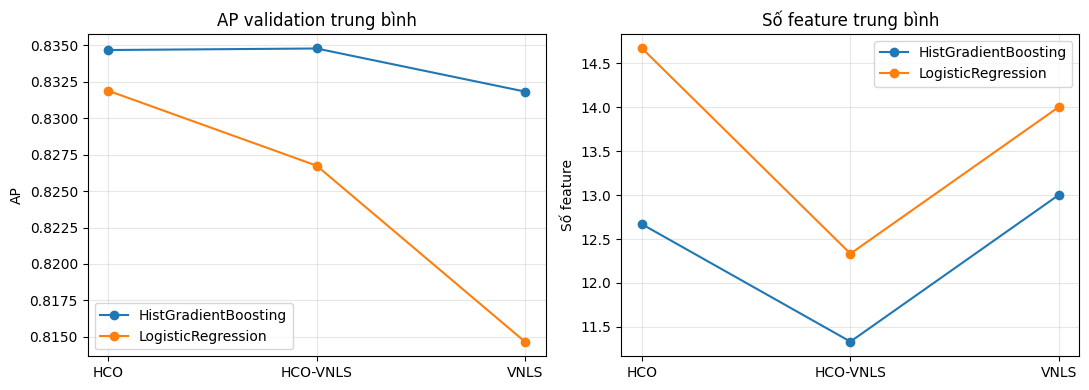

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for model_name, group in summary.groupby('model'):
    axes[0].plot(group['method'], group['mean_validation_ap'], marker='o', label=model_name)
    axes[1].plot(group['method'], group['mean_features'], marker='o', label=model_name)
axes[0].set_title('AP validation trung bình')
axes[0].set_ylabel('AP')
axes[1].set_title('Số feature trung bình')
axes[1].set_ylabel('Số feature')
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'so_sanh_hco_vnls_theo_mo_hinh.png', dpi=160)
plt.show()


## 4. Cách đọc kết quả

- Nếu HCO+VNLS có AP cao hơn HCO và VNLS trên cả hai model và nhiều seed, đó là bằng chứng ủng hộ hybrid.
- Nếu hybrid chỉ có ít feature hơn nhưng AP thấp hơn, kết luận đúng là hybrid tối ưu độ gọn, chưa chứng minh cải thiện chất lượng dự đoán.
- Nếu kết quả phụ thuộc mạnh vào model hoặc alpha, đó là phát hiện quan trọng: HCO+VNLS không có một cấu hình tốt cho mọi model.
- Chỉ số ở đây là validation screening. Khi chốt cấu hình, phải chạy lại test-lock theo quy trình notebook 09.
